In [107]:
using Revise

using MarineHydro
using PyCall
using StaticArrays
using Meshes


### Create Cylinder mesh using Meshes and get immersed part

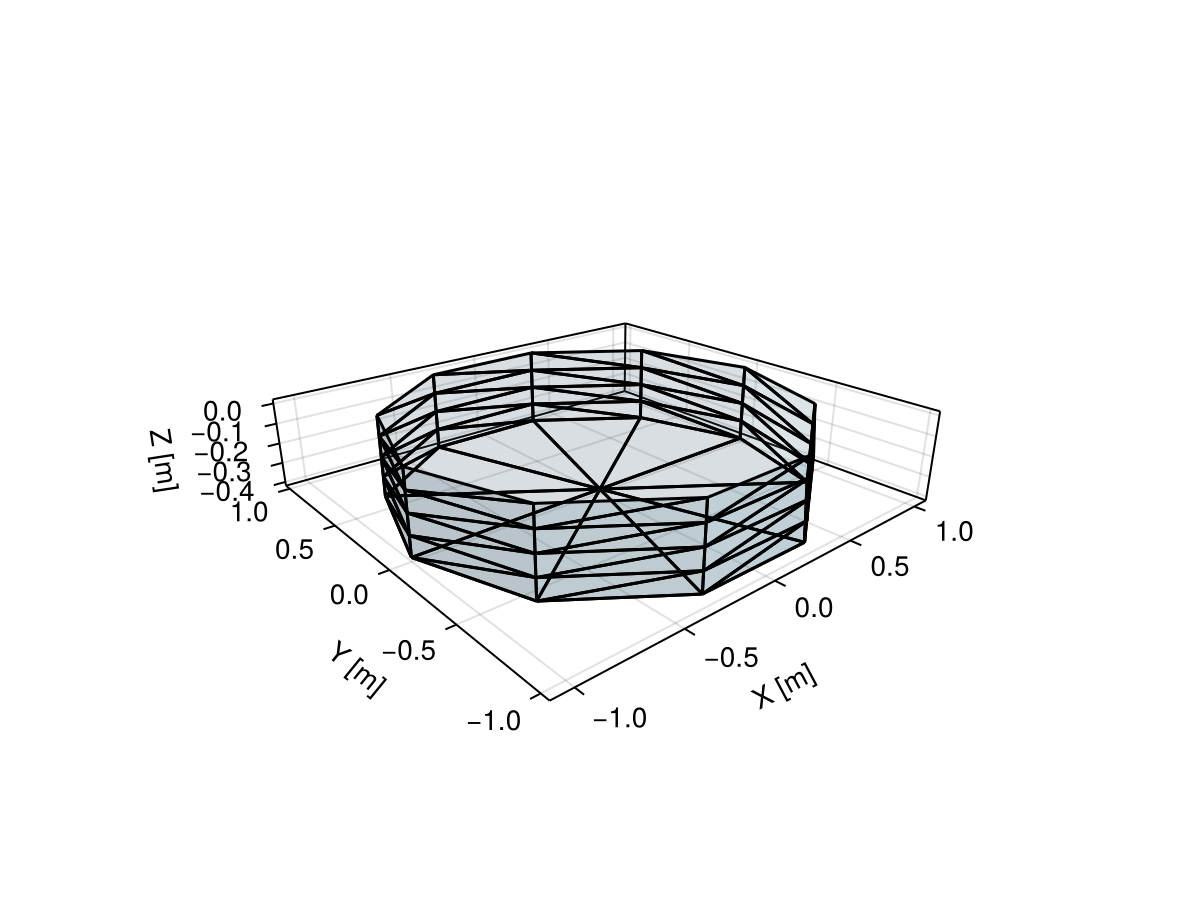

In [108]:
cyl = CylinderSurface(
    Meshes.Point(0.0, 0.0, -0.4),  # bottom center
    Meshes.Point(0.0, 0.0, 0.1),  # top center
    1.0                   # radius
)

cyl_mesh = Meshes.discretize(cyl, RegularDiscretization(10,5))

cyl_body = FloatingBody(cyl_mesh, ["Surge","Sway","Heave","Roll","Pitch","Yaw"], "cyl"; rotation_center=[0.0,0.0,-0.1], center_of_mass=[0.0,0.0,-0.2], mass=1000)
cyl_body = FloatingBody(cyl_mesh, ["Surge","Sway","Heave","Roll","Pitch","Yaw"], "cyl"; rotation_center=[0.0,0.0,-0.1], center_of_mass=[0.0,0.0,-0.2], mass=nothing) # neutrally buoyant

immersed_cyl_body = MarineHydro.get_immersed_part(cyl_body)

viz(immersed_cyl_body.mesh;
    color = :skyblue,
    alpha = 0.2,
    showsegments = true,
    segmentcolor = :black
)

### Set up mesh in Capytaine and convert to Meshes for comparison

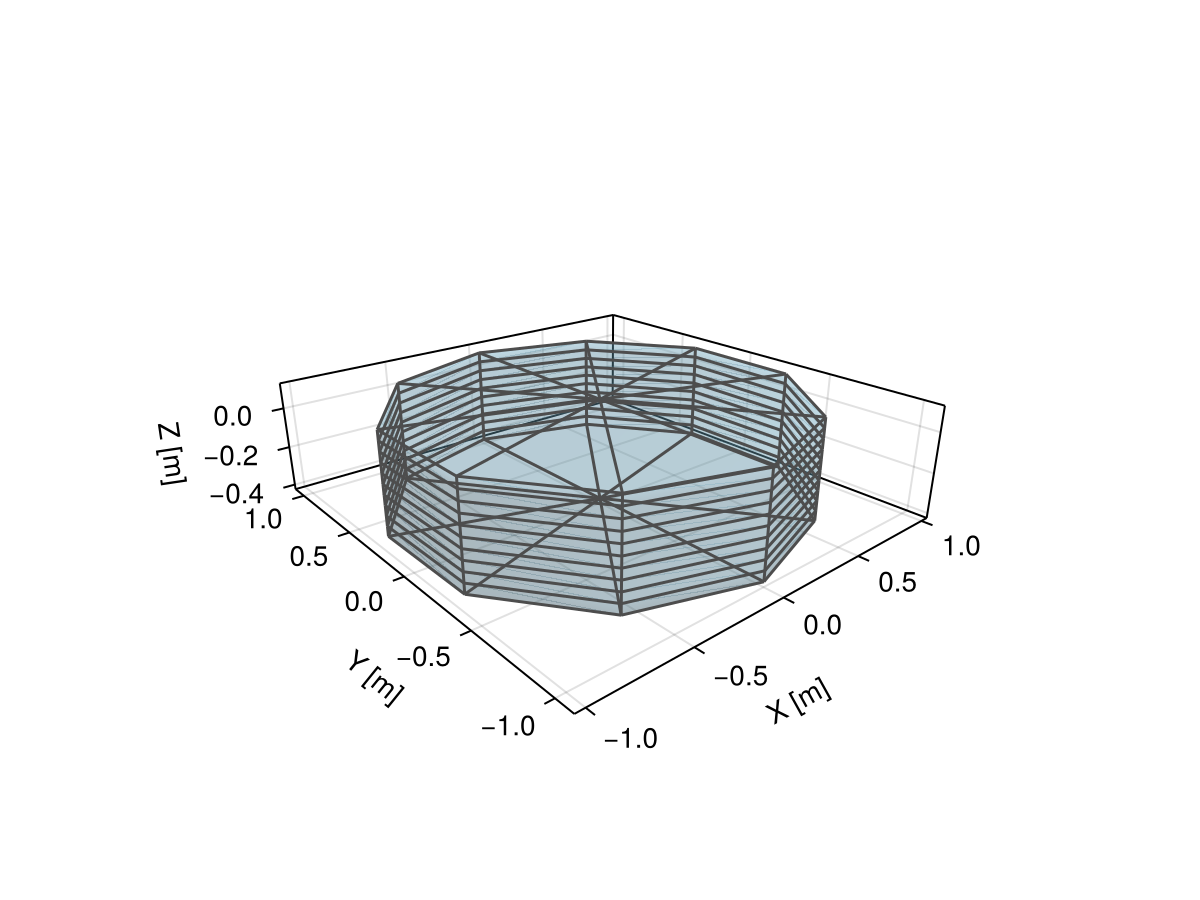

In [109]:
cpt = pyimport("capytaine")

cpt_cyl_mesh = cpt.mesh_vertical_cylinder(
    radius = 1.0,
    length = 0.5,
    center = (0.0, 0.0, -0.15),
    resolution = (1, 10, 10),
    name = "cyl"
)

cpt_cyl_mesh.quadrature_method = "Gauss-Legendre 2"

mass = 1000.0

cpt_body = cpt.FloatingBody(
    mesh = cpt_cyl_mesh,
    dofs = cpt.rigid_body_dofs(
        rotation_center = (0.0, 0.0, -0.1)
    ),
    center_of_mass = (0.0, 0.0, -0.2),
    name = "cyl",
    mass = mass
)

function capytaine_mesh_to_meshes(cpt_mesh)
    verts = Array(cpt_mesh.vertices)
    faces = Array(cpt_mesh.faces)

    points = [
        Meshes.Point(verts[i, 1], verts[i, 2], verts[i, 3])
        for i in 1:size(verts, 1)
    ]

    connec = Meshes.Connectivity[]

    for i in 1:size(faces, 1)
        # Python indices are 0-based, so add 1
        inds = Int.(faces[i, :]) .+ 1

        # Some triangle faces may repeat last index; remove duplicates
        inds = unique(inds)

        if length(inds) == 3
            push!(connec, Meshes.connect(Tuple(inds), Meshes.Triangle))
        elseif length(inds) == 4
            push!(connec, Meshes.connect(Tuple(inds), Meshes.Quadrangle))
        else
            @warn "Skipping face with unsupported vertex count" face=i nvertices=length(inds)
        end
    end

    return Meshes.SimpleMesh(points, connec)
end

jl_cpt_mesh = capytaine_mesh_to_meshes(cpt_cyl_mesh)

jl_cpt_body = FloatingBody(
    jl_cpt_mesh,
    ["Surge","Sway","Heave","Roll","Pitch","Yaw"],
    "cyl";
    rotation_center = [0.0, 0.0, -0.1],
    center_of_mass = [0.0, 0.0, -0.2],
    mass = mass_total
)

viz(jl_cpt_mesh; color=:skyblue, alpha=0.25, showsegments=true)

### Set up functions for comparisons

In [110]:
scalar_key_map = [
    (:g, "g"),
    (:rho, "rho"),
    (:wet_surface_area, "wet_surface_area"),

    (:displaced_volume, "disp_volume"),
    (:displaced_mass, "disp_mass"),

    (:waterplane_area, "waterplane_area"),
    (:transversal_metacentric_radius, "transversal_metacentric_radius"),
    (:longitudinal_metacentric_radius, "longitudinal_metacentric_radius"),
    (:transversal_metacentric_height, "transversal_metacentric_height"),
    (:longitudinal_metacentric_height, "longitudinal_metacentric_height"),
    (:length_overall, "length_overall"),
    (:breadth_overall, "breadth_overall"),
    (:depth, "depth"),
    (:draft, "draught"),
    (:length_at_waterline, "length_at_waterline"),
    (:breadth_at_waterline, "breadth_at_waterline"),
    (:length_overall_submerged, "length_overall_submerged"),
    (:breadth_overall_submerged, "breadth_overall_submerged"),
]

function compare_scalar_hydro(hydrostatics, cpt_hydrostatics; atol=1e-8)
    for (jl_key, cpt_key) in scalar_key_map
        jl = getproperty(hydrostatics, jl_key)
        cpt = Float64(cpt_hydrostatics[cpt_key])

        diff = jl - cpt
        ok = abs(diff) <= atol

        println(rpad(String(jl_key), 35),
            " JL = ", jl,
            " | CPT = ", cpt,
            " | diff = ", diff,
            ok ? " ✅" : " ❌"
        )
    end
end

function compare_vector_hydro(hydrostatics, cpt_hydrostatics; atol=1e-8)
    vector_keys = [
        :center_of_mass,
        :center_of_buoyancy,
        :waterplane_center,
    ]

    for key in vector_keys
        jl = collect(getproperty(hydrostatics, key))
        cpt = Float64.(collect(cpt_hydrostatics[String(key)]))

        diff = jl .- cpt
        ok = maximum(abs.(diff)) <= atol

        println(String(key), ok ? " ✅" : " ❌")
        println("  JL   = ", jl)
        println("  CPT  = ", cpt)
        println("  diff = ", diff)
    end
end

function _reorder_cpt_matrix(xr_matrix, target_dofs)
    dofs_str = String.(target_dofs)

    xr_reordered = xr_matrix.sel(
        influenced_dof = dofs_str,
        radiating_dof = dofs_str
    )

    return Array(xr_reordered.values)
end

function compare_matrix_hydro(hydrostatics, cpt_hydrostatics; atol=1e-8)
    # Hydrostatic stiffness
    K_jl = hydrostatics.hydrostatic_stiffness
    K_cpt = _reorder_cpt_matrix(
        cpt_hydrostatics["hydrostatic_stiffness"],
        hydrostatics.hydrostatic_stiffness_dofs
    )

    Kdiff = K_jl .- K_cpt

    println("hydrostatic_stiffness ",
        maximum(abs.(Kdiff)) <= atol ? "✅" : "❌")
    println("max diff = ", maximum(abs.(Kdiff)))
    display(Kdiff)

    # Inertia matrix
    if hydrostatics.inertia_matrix === nothing || !haskey(cpt_hydrostatics, "inertia_matrix")
        println("inertia_matrix skipped")
        return
    end

    M_jl = hydrostatics.inertia_matrix
    M_cpt = _reorder_cpt_matrix(
        cpt_hydrostatics["inertia_matrix"],
        hydrostatics.inertia_matrix_dofs
    )

    Mdiff = M_jl .- M_cpt

    println("inertia_matrix ",
        maximum(abs.(Mdiff)) <= atol ? "✅" : "❌")
    println("max diff = ", maximum(abs.(Mdiff)))
    display(Mdiff)
end

compare_matrix_hydro (generic function with 1 method)

### Compare Marine Hydro hydrostatics to Capytaine to verify. Note that the inertia matrix is off due to current Capytaine implementation; see Issue #992 on Capytaine.

In [111]:
hydrostatics = MarineHydro.get_hydrostatics(jl_cpt_body; quadrature=:tri3)
cpt_hydrostatics = cpt_body.compute_hydrostatics(g=9.81, rho=1025)

compare_scalar_hydro(hydrostatics, cpt_hydrostatics)
compare_vector_hydro(hydrostatics, cpt_hydrostatics)
compare_matrix_hydro(hydrostatics, cpt_hydrostatics)

[ Info: Computing hydrostatics on immersed part of body.


g                                   JL = 9.81 | CPT = 9.81 | diff = 0.0 ✅
rho                                 JL = 1025.0 | CPT = 1025.0 | diff = 0.0 ✅
wet_surface_area                    JL = 5.411062216461939 | CPT = 5.411062216461944 | diff = -4.440892098500626e-15 ✅
displaced_volume                    JL = 1.175570504584946 | CPT = 1.1755705045849474 | diff = -1.3322676295501878e-15 ✅
displaced_mass                      JL = 1204.9597671995698 | CPT = 1204.9597671995712 | diff = -1.3642420526593924e-12 ✅
waterplane_area                     JL = 2.9389262614623664 | CPT = 2.938926261462365 | diff = 1.3322676295501878e-15 ✅
transversal_metacentric_radius      JL = 0.5852118738281141 | CPT = 0.5852118738281132 | diff = 8.881784197001252e-16 ✅
longitudinal_metacentric_radius     JL = 0.5852118738281142 | CPT = 0.5852118738281133 | diff = 8.881784197001252e-16 ✅
transversal_metacentric_height      JL = 0.585211873828114 | CPT = 0.5852118738281133 | diff = 6.661338147750939e-16 ✅
longitu

6×6 Matrix{Float64}:
 0.0  0.0   0.0           0.0           0.0          0.0
 0.0  0.0   0.0           0.0           0.0          0.0
 0.0  0.0   1.45519e-11  -7.67495e-13   1.26353e-12  0.0
 0.0  0.0  -7.67495e-13   9.09495e-13  -1.19921e-14  1.70513e-13
 0.0  0.0   1.26353e-12  -1.19921e-14   9.09495e-13  1.17741e-13
 0.0  0.0   0.0           0.0           0.0          0.0


inertia_matrix ❌
max diff = 199.99999999999886


6×6 Matrix{Float64}:
 200.0    0.0    0.0   0.0          -20.0           0.0
   0.0  200.0    0.0  20.0            0.0           0.0
   0.0    0.0  200.0   0.0            0.0           0.0
   0.0   20.0    0.0  48.1893         3.54155e-15  -1.77077e-16
 -20.0    0.0    0.0   3.54155e-15   48.1893        2.0659e-16
   0.0    0.0    0.0  -1.77077e-16    2.0659e-16   87.1008

### Compare multibody hydrostatics to Capytaine. 

In [112]:
# test capytaine combining bodies

cpt_cyl_mesh = cpt.mesh_vertical_cylinder(
    radius = 0.5,
    length = 0.5,
    center = (0.0, 0.0, -0.15),
    resolution = (1, 10, 10),
    name = "cyl1"
)
cpt_cyl_mesh.quadrature_method = "Gauss-Legendre 2"

cpt_body_1 = cpt.FloatingBody(
    mesh = cpt_cyl_mesh,
    dofs = cpt.rigid_body_dofs(
        rotation_center = (0.0, 0.0, -0.1)
    ),
    center_of_mass = (0.0, 0.0, -0.2),
    name = "cyl1",
    mass = 1000
)

cpt_cyl_mesh = cpt.mesh_vertical_cylinder(
    radius = 0.5,
    length = 0.5,
    center = (1.0, 0.0, -0.15),
    resolution = (1, 10, 10),
    name = "cyl2"
)
cpt_cyl_mesh.quadrature_method = "Gauss-Legendre 2"

cpt_body_2 = cpt.FloatingBody(
    mesh = cpt_cyl_mesh,
    dofs = cpt.rigid_body_dofs(
        rotation_center = (1.0, 0.0, -0.1)
    ),
    center_of_mass = (1.0, 0.0, -0.2),
    name = "cyl2",
    mass = 1000
)

cpt_both = cpt_body_1 + cpt_body_2

jl_cpt_mesh_1 = capytaine_mesh_to_meshes(cpt_body_1.mesh)
jl_cpt_mesh_2 = capytaine_mesh_to_meshes(cpt_body_2.mesh)

jl_cpt_body_1 = FloatingBody(
    jl_cpt_mesh_1,
    ["Surge", "Sway", "Heave", "Roll", "Pitch", "Yaw"],
    "cyl1";
    rotation_center = [0.0, 0.0, -0.1],
    center_of_mass = [0.0, 0.0, -0.2],
    mass = Float64(cpt_body_1.mass)
)

jl_cpt_body_2 = FloatingBody(
    jl_cpt_mesh_2,
    ["Surge", "Sway", "Heave", "Roll", "Pitch", "Yaw"],
    "cyl2";
    rotation_center = [1.0, 0.0, -0.1],
    center_of_mass = [1.0, 0.0, -0.2],
    mass = Float64(cpt_body_2.mass)
)

mb = MultiFloatingBody([jl_cpt_body_1, jl_cpt_body_2], "cyl_both")

function compare_multibody_hydro(jl_hydro, cpt_hydro; names=keys(jl_hydro), atol=1e-8)
    for name in mb.body_names
        compare_scalar_hydro(getproperty(jl_hydro, name), cpt_hydro[name])
        compare_vector_hydro(getproperty(jl_hydro, name), cpt_hydro[name])
        compare_matrix_hydro(getproperty(jl_hydro, name), cpt_hydro[name])
    end
end

jl_hydro = MarineHydro.get_hydrostatics(mb)

cpt_hydro = Dict(
    :cyl1 => cpt_body_1.compute_hydrostatics(g=9.81, rho=1025),
    :cyl2 => cpt_body_2.compute_hydrostatics(g=9.81, rho=1025)
)

compare_multibody_hydro(
    jl_hydro,
    cpt_hydro;
    names=[:cyl1, :cyl2],
    atol=1e-8
)

[ Info: Computing hydrostatics on immersed part of body.
[ Info: Computing hydrostatics on immersed part of body.


g                                   JL = 9.81 | CPT = 9.81 | diff = 0.0 ✅
rho                                 JL = 1025.0 | CPT = 1025.0 | diff = 0.0 ✅
wet_surface_area                    JL = 1.970799542865378 | CPT = 1.9707995428653804 | diff = -2.4424906541753444e-15 ✅
displaced_volume                    JL = 0.2938926261462365 | CPT = 0.29389262614623685 | diff = -3.3306690738754696e-16 ✅
displaced_mass                      JL = 301.23994179989245 | CPT = 301.2399417998928 | diff = -3.410605131648481e-13 ✅
waterplane_area                     JL = 0.7347315653655916 | CPT = 0.7347315653655913 | diff = 3.3306690738754696e-16 ✅
transversal_metacentric_radius      JL = 0.14630296845702853 | CPT = 0.1463029684570283 | diff = 2.220446049250313e-16 ✅
longitudinal_metacentric_radius     JL = 0.14630296845702856 | CPT = 0.14630296845702834 | diff = 2.220446049250313e-16 ✅
transversal_metacentric_height      JL = 0.14630296845702842 | CPT = 0.14630296845702845 | diff = -2.7755575615628914e-1

6×6 Matrix{Float64}:
 0.0  0.0   0.0           0.0           0.0          0.0
 0.0  0.0   0.0           0.0           0.0          0.0
 0.0  0.0   3.63798e-12  -9.59369e-14   1.57942e-13  0.0
 0.0  0.0  -9.59369e-14  -2.27374e-13  -7.49507e-16  2.13141e-14
 0.0  0.0   1.57942e-13  -7.49507e-16  -2.27374e-13  1.47176e-14
 0.0  0.0   0.0           0.0           0.0          0.0

inertia_matrix ❌
max diff = 199.99999999999886


6×6 Matrix{Float64}:
 200.0    0.0    0.0   0.0          -20.0           0.0
   0.0  200.0    0.0  20.0            0.0           0.0
   0.0    0.0  200.0   0.0            0.0           0.0
   0.0   20.0    0.0  15.5265         8.85386e-16  -8.85386e-17
 -20.0    0.0    0.0   8.85386e-16   15.5265        1.03295e-16
   0.0    0.0    0.0  -8.85386e-17    1.03295e-16  21.7752

g                                   JL = 9.81 | CPT = 9.81 | diff = 0.0 ✅
rho                                 JL = 1025.0 | CPT = 1025.0 | diff = 0.0 ✅
wet_surface_area                    JL = 1.9707995428653777 | CPT = 1.9707995428653806 | diff = -2.886579864025407e-15 ✅
displaced_volume                    JL = 0.2938926261462367 | CPT = 0.2938926261462365 | diff = 1.6653345369377348e-16 ✅
displaced_mass                      JL = 301.2399417998926 | CPT = 301.23994179989245 | diff = 1.7053025658242404e-13 ✅
waterplane_area                     JL = 0.7347315653655915 | CPT = 0.7347315653655913 | diff = 2.220446049250313e-16 ✅
transversal_metacentric_radius      JL = 0.14630296845702845 | CPT = 0.14630296845702848 | diff = -2.7755575615628914e-17 ✅
longitudinal_metacentric_radius     JL = 2.6463029684570274 | CPT = 2.6463029684570283 | diff = -8.881784197001252e-16 ✅
transversal_metacentric_height      JL = 0.14630296845702848 | CPT = 0.14630296845702842 | diff = 5.551115123125783e-17 ✅

6×6 Matrix{Float64}:
 0.0  0.0   0.0          0.0           0.0           0.0
 0.0  0.0   0.0          0.0           0.0           0.0
 0.0  0.0   2.72848e-12  1.61348e-13  -4.29263e-13   0.0
 0.0  0.0   1.61348e-13  2.27374e-13   4.56518e-14   1.31236e-12
 0.0  0.0  -4.29263e-13  4.56518e-14   2.27374e-13  -9.75722e-14
 0.0  0.0   0.0          0.0           0.0           0.0

inertia_matrix ❌
max diff = 199.99999999999943


6×6 Matrix{Float64}:
 200.0    0.0    0.0   0.0          -20.0           0.0
   0.0  200.0    0.0  20.0            0.0           0.0
   0.0    0.0  200.0   0.0            0.0           0.0
   0.0   20.0    0.0  15.5265        -1.47564e-15  -3.92521e-15
 -20.0    0.0    0.0  -1.47564e-15   15.5265       -1.32808e-16
   0.0    0.0    0.0  -3.92521e-15   -1.32808e-16  21.7752

### Compare generalized body mode approach to Capytaine.

In [113]:
rho = 1025.0
g = 9.81

# Face centers of immersed mesh
centers = Array(cpt_immersed.mesh.faces_centers)
nfaces = size(centers, 1)

xc, yc, zc = 0.0, 0.0, -0.1

x = centers[:, 1] .- xc
y = centers[:, 2] .- yc
z = centers[:, 3] .- zc

# Generalized versions of some rigid-like modes
gheave = zeros(Float64, nfaces, 3)
gheave[:, 3] .= 1.0

groll = zeros(Float64, nfaces, 3)
groll[:, 2] .= -z
groll[:, 3] .= y

gpitch = zeros(Float64, nfaces, 3)
gpitch[:, 1] .= z
gpitch[:, 3] .= -x

# Flexible mode: BendX, V = [0, 0, x_global]
bendx = zeros(Float64, nfaces, 3)
bendx[:, 3] .= centers[:, 1]

# Flexible mode: Radial, V = [x_global, y_global, 0]
radial = zeros(Float64, nfaces, 3)
radial[:, 1] .= centers[:, 1]
radial[:, 2] .= centers[:, 2]

# Divergences
zero_div = zeros(Float64, nfaces)
bendx_div = zeros(Float64, nfaces)
radial_div = fill(2.0, nfaces)

# Capytaine generalized-only DOFs
cpt_gen_dofs = PyDict(Dict(
    "GHeave" => gheave,
    "GRoll" => groll,
    "GPitch" => gpitch,
    "BendX" => bendx,
    "Radial" => radial,
))

cpt_gen_divergence = Dict(
    "GHeave" => zero_div,
    "GRoll" => zero_div,
    "GPitch" => zero_div,
    "BendX" => bendx_div,
    "Radial" => radial_div,
)

cpt_gen_body = cpt.FloatingBody(
    mesh = cpt_immersed.mesh,
    dofs = cpt_gen_dofs,
    center_of_mass = (0.0, 0.0, -0.2),
    name = "cyl_gen",
    mass = nothing
)

cpt_gen_hs = cpt_gen_body.compute_hydrostatics(
    divergence = cpt_gen_divergence,
    rho = rho,
    g = g
)

# Convert the same immersed Capytaine mesh to Meshes.jl
jl_gen_mesh = capytaine_mesh_to_meshes(cpt_immersed.mesh)

# Same generalized-only DOFs
jl_gen_dofs = (
    GHeave = PanelDofMode(gheave; divergence=zero_div),
    GRoll  = PanelDofMode(groll;  divergence=zero_div),
    GPitch = PanelDofMode(gpitch; divergence=zero_div),
    BendX  = PanelDofMode(bendx;  divergence=bendx_div),
    Radial = PanelDofMode(radial; divergence=radial_div),
)

jl_gen_body = FloatingBody(
    jl_gen_mesh,
    nothing,
    jl_gen_dofs,
    "cyl_gen",
    [0.0, 0.0, -0.2],
    [0.0, 0.0, -0.1],
    nothing
)

jl_gen_hs = MarineHydro.get_hydrostatics(
    jl_gen_body;
    rho = rho,
    g = g,
    free_surface = 0.0,
    water_depth = Inf
)

compare_scalar_hydro(jl_gen_hs, cpt_gen_hs)
compare_vector_hydro(jl_gen_hs, cpt_gen_hs)
# compare_matrix_hydro(jl_gen_hs, cpt_gen_hs) # no inertia matrix for generalized-only DOFs

[ Info: Computing hydrostatics on immersed part of body.


g                                   JL = 9.81 | CPT = 9.81 | diff = 0.0 ✅
rho                                 JL = 1025.0 | CPT = 1025.0 | diff = 0.0 ✅
wet_surface_area                    JL = 5.411062216461939 | CPT = 5.411062216461944 | diff = -4.440892098500626e-15 ✅
displaced_volume                    JL = 1.175570504584946 | CPT = 1.1755705045849474 | diff = -1.3322676295501878e-15 ✅
displaced_mass                      JL = 1204.9597671995698 | CPT = 1204.9597671995712 | diff = -1.3642420526593924e-12 ✅
waterplane_area                     JL = 2.9389262614623664 | CPT = 2.938926261462365 | diff = 1.3322676295501878e-15 ✅
transversal_metacentric_radius      JL = 0.5852118738281141 | CPT = 0.5852118738281132 | diff = 8.881784197001252e-16 ✅
longitudinal_metacentric_radius     JL = 0.5852118738281142 | CPT = 0.5852118738281133 | diff = 8.881784197001252e-16 ✅
transversal_metacentric_height      JL = 0.585211873828114 | CPT = 0.5852118738281133 | diff = 6.661338147750939e-16 ✅
longitu